## HLS L30 vs S30: preprocessing and cross-sensor comparison

NASA's Harmonized Landsat Sentinel-2 (HLS) v2.0 project distributes **L30** (from Landsat 8/9 OLI) and **S30** (from Sentinel-2 MSI) on a common 30 m UTM tiling grid, so that a Landsat-derived and a Sentinel-2-derived scene of the same tile are directly stackable.

"Directly stackable" does not mean "directly comparable pixel-for-pixel", though: a given L30/S30 pair is usually acquired days apart, under different sun/view geometry, and each product carries its own cloud mask and swath footprint. This notebook works through that gap for a single tile pair:

1. Load bands and read their scaling metadata directly from the GeoTIFF tags
2. Decode the Fmask cloud/shadow mask (reusing `HLS.is_cloud`)
3. Intersect the valid-pixel footprints of both products and crop to the shared region
4. Build RGB true-color composites, with a longitude/latitude grid overlaid on each map
5. Cross-check the harmonization with a shared-band NDVI comparison
6. Explore each product's *unique* bands: L30 thermal infrared, S30 red edge

**Scene pair used here** (tile `T52SCG`):

| Product | Sensing date | DOY | Sun zenith |
|---|---|---|---|
| L30 | 2026-03-28 | 087 | 39.7° |
| S30 | 2026-04-08 | 098 | 33.7° |

The two acquisitions are 11 days apart with different sun geometry, so this is a demonstration of **grid/format harmonization**, not a same-moment radiometric cross-calibration. Keep this in mind when reading the NDVI difference in Section 5.

### Data

Raw per-band GeoTIFFs from NASA LP DAAC (HLSL30 / HLSS30 v2.0), downloaded via [Earthdata Search](https://search.earthdata.nasa.gov/). See `README.md` in this folder for how to point this notebook at your own download via the `HLS_L30_DIR` / `HLS_S30_DIR` environment variables.

In [ ]:
import os
import sys
import warnings
from glob import glob

import matplotlib.pyplot as plt
import numpy as np
import pyproj
import rasterio

warnings.filterwarnings(
    "ignore", message="Setting the shape on a NumPy array.*", category=DeprecationWarning
)  # rasterio's C reader trips this on NumPy 2.5 for every band read; harmless, but noisy

sys.path.insert(0, os.path.abspath(os.path.join("..", "..")))
import HLS

L30_DIR = os.environ.get("HLS_L30_DIR", os.path.join("data", "hls_l30"))
S30_DIR = os.environ.get("HLS_S30_DIR", os.path.join("data", "hls_s30"))


def granule_id(directory):
    """Infer the HLS granule ID (e.g. HLS.L30.T52SCG.2026087T021044.v2.0) from any .tif in the folder."""
    sample = glob(os.path.join(directory, "*.tif"))[0]
    return ".".join(os.path.basename(sample).split(".")[:6])


L30_ID = granule_id(L30_DIR)
S30_ID = granule_id(S30_DIR)
print("L30 granule:", L30_ID)
print("S30 granule:", S30_ID)

### 1. Load bands, scaled by their own GeoTIFF tags

Each HLS band GeoTIFF carries its own `scale_factor` (and, for thermal bands, `unit`) in its tags. Reading these directly instead of hardcoding them is safer: it is the same value the LP DAAC processing pipeline used, and it makes the difference between reflectance bands (`scale_factor=0.0001`) and L30's thermal bands (`scale_factor=0.01`, already in Celsius) explicit.

Band naming differs between the two products (L30 lacks red edge and B08/B09-water-vapor; S30 lacks thermal), so each gets its own nickname → band-code mapping.

In [26]:
L30_BANDS = {
    "blue": "B02", "green": "B03", "red": "B04", "nir": "B05", "tir1": "B10",
}
S30_BANDS = {
    "blue": "B02", "green": "B03", "red": "B04",
    "red_edge1": "B05", "nir_broad": "B08", "nir": "B8A",
}
# Only the bands this notebook actually uses (RGB + NDVI + L30 thermal + S30 red edge) are
# loaded. HLS L30/S30 granules carry more bands than this (see HLS.py's BandReader for the
# full set), but each band is a full 3660x3660 float32 array (~50 MB), so loading all of them
# for both products is unnecessary memory pressure for what this notebook demonstrates.


def load_band(directory, product_id, band_code):
    """Read one HLS band GeoTIFF, applying its own scale_factor tag and masking nodata to NaN.

    Returns (data, transform, crs, unit) where unit is None for reflectance bands
    and "Celsius" for the L30 thermal bands.
    """
    path = os.path.join(directory, f"{product_id}.{band_code}.tif")
    with rasterio.open(path) as src:
        raw = src.read(1)
        tags = src.tags()
        scale = float(tags.get("scale_factor", 1.0))
        data = raw.astype("float32")
        data[raw == src.nodata] = np.nan
        data *= scale
        return data, src.transform, src.crs, tags.get("unit")


def load_fmask(directory, product_id):
    """Read the Fmask QA band (uint8, fill value 255)."""
    path = os.path.join(directory, f"{product_id}.Fmask.tif")
    with rasterio.open(path) as src:
        return src.read(1)


l30 = {name: load_band(L30_DIR, L30_ID, code) for name, code in L30_BANDS.items()}
s30 = {name: load_band(S30_DIR, S30_ID, code) for name, code in S30_BANDS.items()}

transform = l30["red"][1]
crs = l30["red"][2]
assert s30["red"][1] == transform and s30["red"][2] == crs, "L30/S30 grids do not match"

print("Grid: shape", l30["red"][0].shape, "| CRS", crs)
print("L30 TIR1 unit:", l30["tir1"][3])
print("S30 red_edge1 unit:", s30["red_edge1"][3])

Grid: shape (3660, 3660) | CRS EPSG:32652
L30 TIR1 unit: Celsius
S30 red_edge1 unit: None


### 2. Cloud / shadow masking

HLS Fmask uses the same bit layout for both L30 and S30, so the existing `HLS.is_cloud` bit-decoder (originally written for the merged-product `BandReader`) applies directly to these raw per-granule Fmask bands, so the bit logic does not need to be reimplemented.

`HLS.is_cloud` returns `1` where the pixel is cloud, cloud-shadow, or adjacent to cloud/shadow, and `0` where clear.

In [27]:
l30_fmask = load_fmask(L30_DIR, L30_ID)
s30_fmask = load_fmask(S30_DIR, S30_ID)

l30_clear = (HLS.is_cloud(l30_fmask) == 0) & (l30_fmask != 255)  # exclude cloud/shadow and Fmask fill
s30_clear = (HLS.is_cloud(s30_fmask) == 0) & (s30_fmask != 255)

print(f"L30 clear fraction: {l30_clear.mean():.1%}")
print(f"S30 clear fraction: {s30_clear.mean():.1%}")

L30 clear fraction: 74.8%
S30 clear fraction: 98.6%


### 3. Intersect valid footprints and crop to the shared ROI

L30 and S30 already share the exact same UTM grid and extent (checked with an `assert` above), so there is no reprojection to do. What differs between them is *which pixels actually have usable data*:

- **Nodata**: a granule's Landsat/Sentinel-2 swath does not necessarily cover the full HLS tile, so part of the grid can be fill value on either side.
- **Cloud/shadow**: decoded above from Fmask.
- **Implausible reflectance**: HLS surface reflectance can carry small negative values from the atmospheric correction at very dark pixels. Those aren't flagged by Fmask, but they blow up ratio indices like NDVI (near-zero denominator), so we also restrict to the physically valid reflectance range `[0, 1]` for the bands used in ratio indices.

The "common ROI" is the bounding box of pixels valid in **both** products simultaneously.

In [28]:
def in_reflectance_range(band, lo=0.0, hi=1.0):
    return (band >= lo) & (band <= hi)


l30_valid = (
    (~np.isnan(l30["red"][0])) & l30_clear
    & in_reflectance_range(l30["red"][0]) & in_reflectance_range(l30["nir"][0])
)
s30_valid = (
    (~np.isnan(s30["red"][0])) & s30_clear
    & in_reflectance_range(s30["red"][0]) & in_reflectance_range(s30["nir"][0])
)
both_valid = l30_valid & s30_valid

rows = np.where(both_valid.any(axis=1))[0]
cols = np.where(both_valid.any(axis=0))[0]
row_slice = slice(rows.min(), rows.max() + 1)
col_slice = slice(cols.min(), cols.max() + 1)


def crop(array_2d):
    return array_2d[row_slice, col_slice]


roi_mask = crop(both_valid)
roi_transform = rasterio.Affine(
    transform.a, transform.b, transform.c + col_slice.start * transform.a,
    transform.d, transform.e, transform.f + row_slice.start * transform.e,
)

print(f"Both-valid fraction over full tile: {both_valid.mean():.1%}")
print(f"Crop window: rows {row_slice.start}-{row_slice.stop}, cols {col_slice.start}-{col_slice.stop}")
print(f"Cropped shape: {roi_mask.shape}, valid fraction within crop: {roi_mask.mean():.1%}")

Both-valid fraction over full tile: 72.9%
Crop window: rows 0-3660, cols 0-3277
Cropped shape: (3660, 3277), valid fraction within crop: 81.5%


### 4. RGB true-color composites

Both composites are built the same way: stack red/green/blue reflectance, mask to the shared ROI, and apply a percentile stretch for contrast (raw surface reflectance values are low, so a naive 0-1 stretch looks nearly black). Every map in this notebook (RGB composites, NDVI, thermal, NDRE) is drawn through the same `show_image()` helper, which relabels the UTM tick grid as longitude/latitude so maps stay geographically readable without reprojecting the underlying raster.

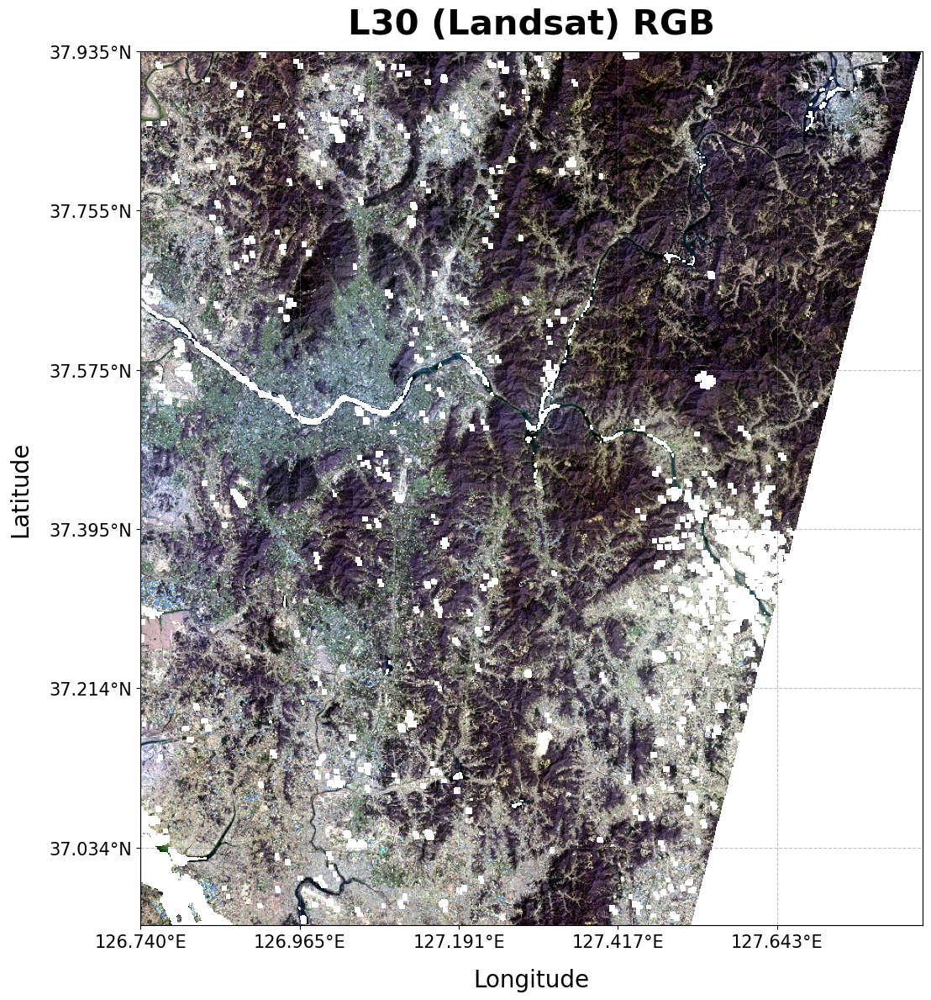

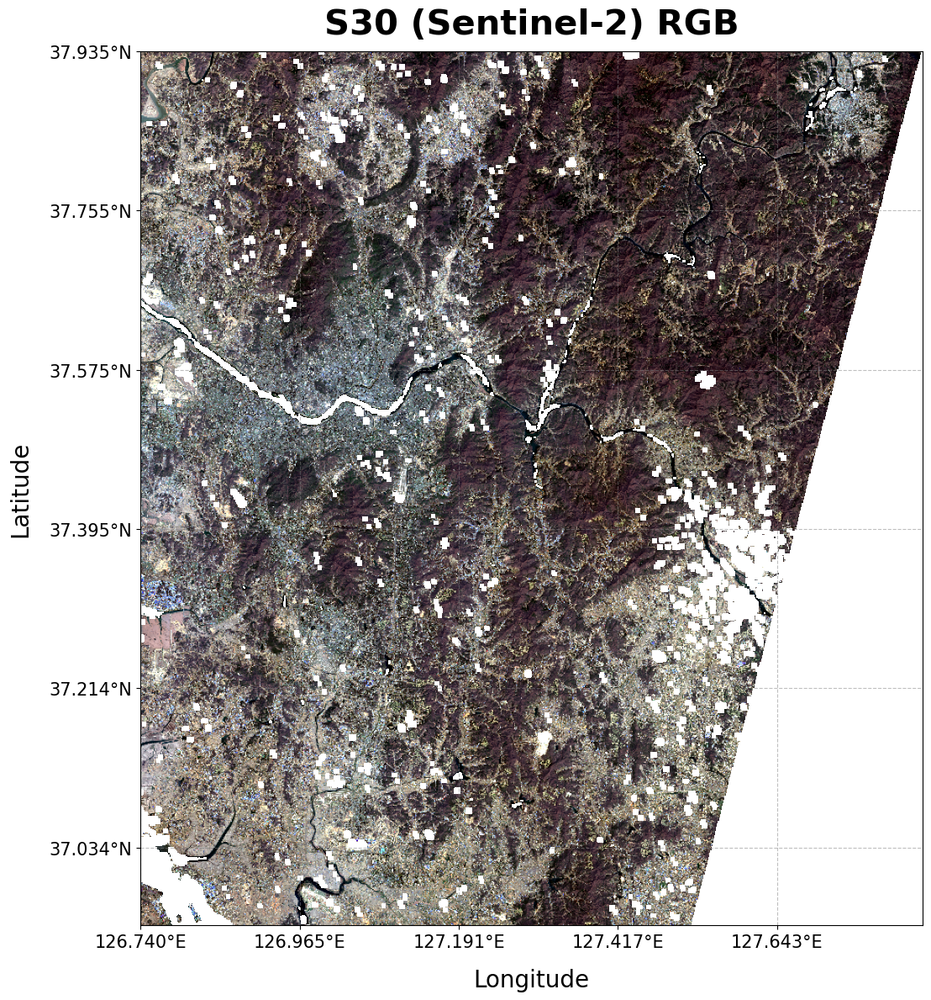

In [29]:
DISPLAY_STRIDE = 4  # decimation factor for imshow only; all numeric stats above use full resolution


def decimate(array_2d):
    return array_2d[::DISPLAY_STRIDE, ::DISPLAY_STRIDE]


def roi_extent(mask_shape):
    """Absolute UTM (west, east, south, north) extent of the ROI, in meters.

    Kept in the ROI's native UTM coordinates (no reprojection of the pixel
    data itself, only of the tick labels; see add_lonlat_grid() below) so
    imshow still only ever draws the already-decimated array; see
    DISPLAY_STRIDE and show_image() for why that decimation matters on this
    machine.
    """
    height, width = mask_shape
    west = roi_transform.c
    north = roi_transform.f
    east = west + width * roi_transform.a
    south = north + height * roi_transform.e  # roi_transform.e is negative
    return [west, east, south, north]


def percentile_stretch(band, mask, lo=2, hi=98):
    valid = band[mask]
    p_lo, p_hi = np.percentile(valid, [lo, hi])
    stretched = np.clip((band - p_lo) / (p_hi - p_lo), 0, 1)
    return np.where(mask, stretched, np.nan)


def rgb_composite(product, mask):
    """Percentile-stretch and stack red/green/blue, decimated for display.

    Decimating before the percentile stretch (rather than after) keeps peak memory down;
    this machine has been observed to run out of memory once several full-resolution
    (~3660x3277) float32 arrays are alive at once.
    """
    red = decimate(crop(product["red"][0]))
    green = decimate(crop(product["green"][0]))
    blue = decimate(crop(product["blue"][0]))
    small_mask = decimate(mask)
    return np.stack(
        [percentile_stretch(red, small_mask), percentile_stretch(green, small_mask), percentile_stretch(blue, small_mask)],
        axis=-1,
    )


AXIS_LABEL_FONTSIZE = 20
AXIS_LABEL_PAD = 15
TICK_LABEL_FONTSIZE = 15
TITLE_FONTSIZE = 30
TITLE_PAD = 15


def add_lonlat_grid(ax, crs):
    """Add a dashed grid and relabel the UTM tick positions as longitude/latitude.

    The image itself stays in its native UTM projection (no reprojection of the
    raster); only each tick's UTM coordinate is converted through pyproj. That
    keeps this as cheap as the plain matplotlib grid it replaces, unlike a full
    cartopy graticule.
    """
    to_lonlat = pyproj.Transformer.from_crs(crs.to_epsg(), 4326, always_xy=True)
    xlim, ylim = ax.get_xlim(), ax.get_ylim()
    xticks = [t for t in ax.get_xticks() if min(xlim) <= t <= max(xlim)]
    yticks = [t for t in ax.get_yticks() if min(ylim) <= t <= max(ylim)]
    x_mid, y_mid = np.mean(xlim), np.mean(ylim)

    lons, _ = to_lonlat.transform(xticks, [y_mid] * len(xticks))
    _, lats = to_lonlat.transform([x_mid] * len(yticks), yticks)

    ax.set_xticks(xticks, [f"{lon:.3f}°E" for lon in lons])
    ax.set_yticks(yticks, [f"{lat:.3f}°N" for lat in lats])
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_xlabel("Longitude", fontsize=AXIS_LABEL_FONTSIZE, labelpad=AXIS_LABEL_PAD)
    ax.set_ylabel("Latitude", fontsize=AXIS_LABEL_FONTSIZE, labelpad=AXIS_LABEL_PAD)
    ax.grid(True, linestyle="--", color="gray", alpha=0.5)


def show_image(data, title, cmap=None, vmin=None, vmax=None, colorbar_label=None):
    """Render one array as its own figure and close it immediately after.

    Displaying multiple large arrays via matplotlib on this machine is only reliable one
    figure at a time with the previous one closed first, otherwise memory use climbs
    until the kernel is killed.
    """
    fig, ax = plt.subplots(figsize=(12, 12))
    im = ax.imshow(data, extent=extent, origin="upper", cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_title(title, fontsize=TITLE_FONTSIZE, fontweight="bold", pad=TITLE_PAD)
    add_lonlat_grid(ax, crs)
    ax.tick_params(axis="both", labelsize=TICK_LABEL_FONTSIZE)
    if cmap is not None:
        cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        cbar.ax.tick_params(labelsize=TICK_LABEL_FONTSIZE)
        if colorbar_label is not None:
            cbar.set_label(colorbar_label, fontsize=AXIS_LABEL_FONTSIZE, labelpad=AXIS_LABEL_PAD)
    fig.tight_layout()
    plt.show()
    plt.close(fig)


extent = roi_extent(roi_mask.shape)

show_image(rgb_composite(l30, roi_mask), "L30 (Landsat) RGB")
show_image(rgb_composite(s30, roi_mask), "S30 (Sentinel-2) RGB")

### 5. Cross-sensor NDVI comparison

Both products have a red band and an NIR band, so both can produce NDVI:

- L30: `(B05 - B04) / (B05 + B04)`, using Landsat OLI's single NIR band
- S30: `(B8A - B04) / (B8A + B04)`, using Sentinel-2's *narrow* NIR band (B8A), which is spectrally closer to Landsat's B05 than the broader B08

If harmonization is working as intended, the two NDVI maps should agree closely on land cover pattern, with residual differences attributable to the 11-day acquisition gap and sensor/geometry differences rather than to a grid mismatch.

L30 NDVI: mean=0.292, std=0.134
S30 NDVI: mean=0.353, std=0.157
NDVI diff (S30 - L30): mean=0.061, std=0.064


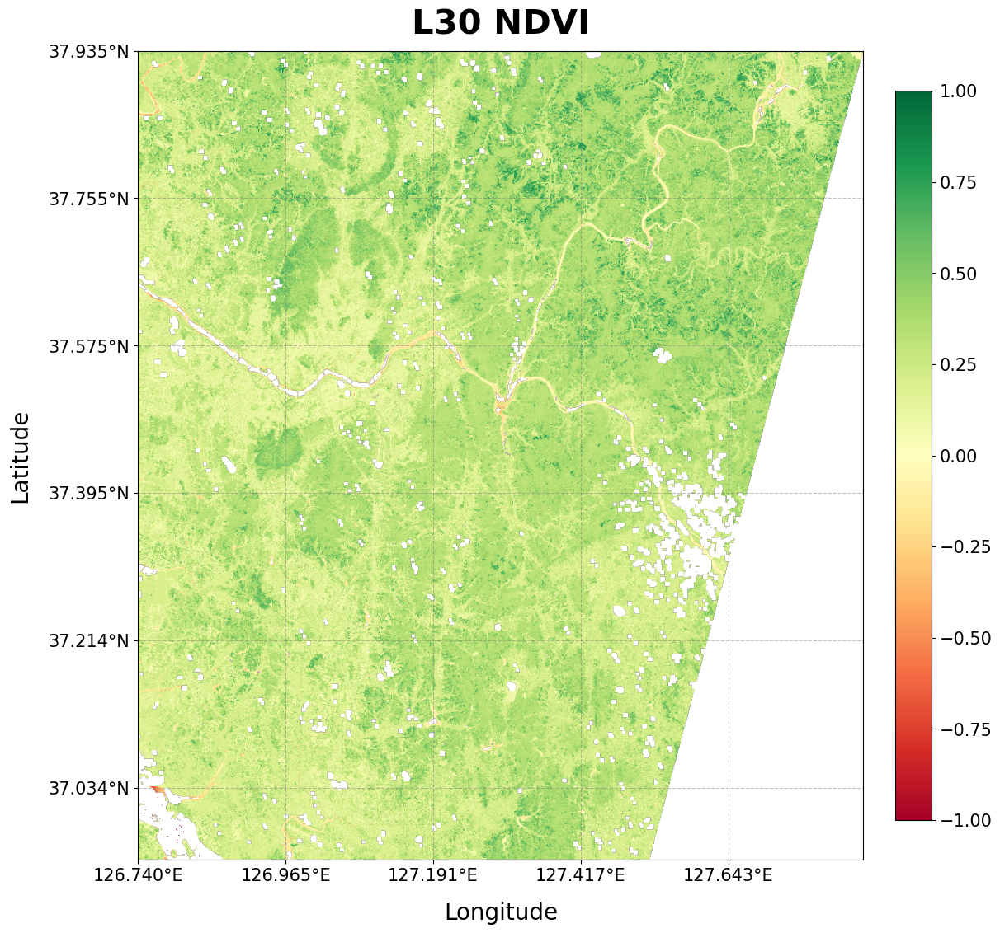

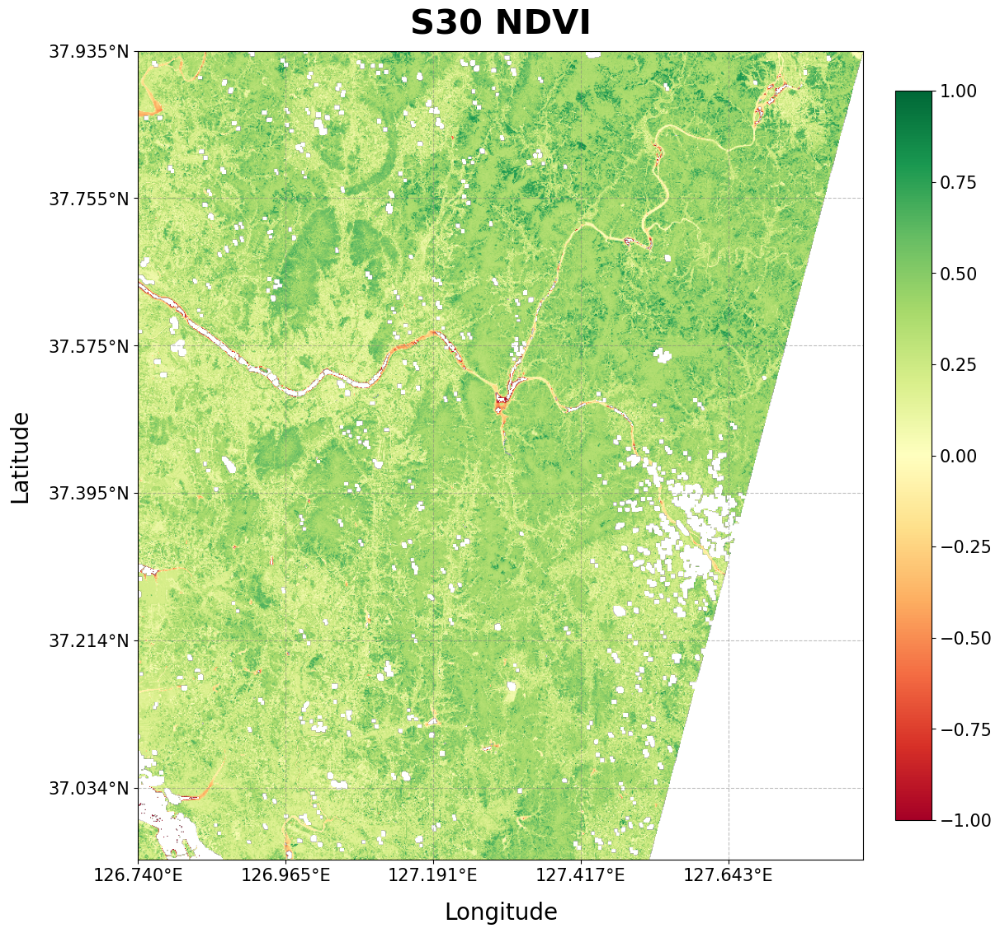

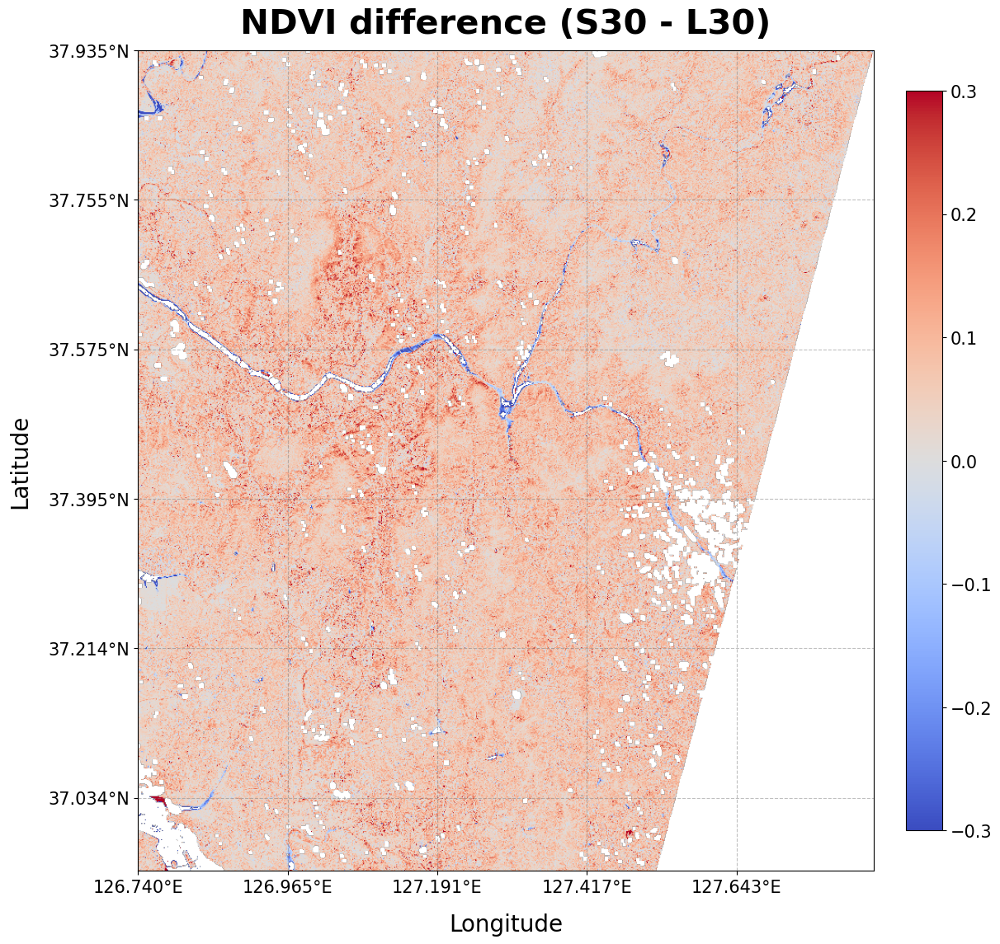

In [30]:
def normalized_difference(a, b):
    """(a - b) / (a + b), with the zero-denominator case set to NaN instead of +/-inf."""
    denom = a + b
    with np.errstate(invalid="ignore", divide="ignore"):
        nd = (a - b) / denom
    return np.where(denom == 0, np.nan, nd)


ndvi_l30 = np.where(roi_mask, normalized_difference(crop(l30["nir"][0]), crop(l30["red"][0])), np.nan)
ndvi_s30 = np.where(roi_mask, normalized_difference(crop(s30["nir"][0]), crop(s30["red"][0])), np.nan)
ndvi_diff = ndvi_s30 - ndvi_l30

print(f"L30 NDVI: mean={np.nanmean(ndvi_l30):.3f}, std={np.nanstd(ndvi_l30):.3f}")
print(f"S30 NDVI: mean={np.nanmean(ndvi_s30):.3f}, std={np.nanstd(ndvi_s30):.3f}")
print(f"NDVI diff (S30 - L30): mean={np.nanmean(ndvi_diff):.3f}, std={np.nanstd(ndvi_diff):.3f}")

show_image(decimate(ndvi_l30), "L30 NDVI", cmap="RdYlGn", vmin=-1, vmax=1)
show_image(decimate(ndvi_s30), "S30 NDVI", cmap="RdYlGn", vmin=-1, vmax=1)
show_image(decimate(ndvi_diff), "NDVI difference (S30 - L30)", cmap="coolwarm", vmin=-0.3, vmax=0.3)

### 6a. L30-only: thermal infrared (surface brightness temperature)

Landsat OLI/TIRS carries two thermal bands that Sentinel-2 MSI does not have at all. HLS L30 already scales these to **degrees Celsius** (`scale_factor=0.01`, `unit=Celsius` in the GeoTIFF tags, see Section 1), so no Planck-law brightness-temperature inversion is needed here; we can plot it directly and compare it against NDVI to see the expected cooling effect of vegetation.

L30 TIR1 (Celsius): mean=18.2, min=-0.2, max=34.3


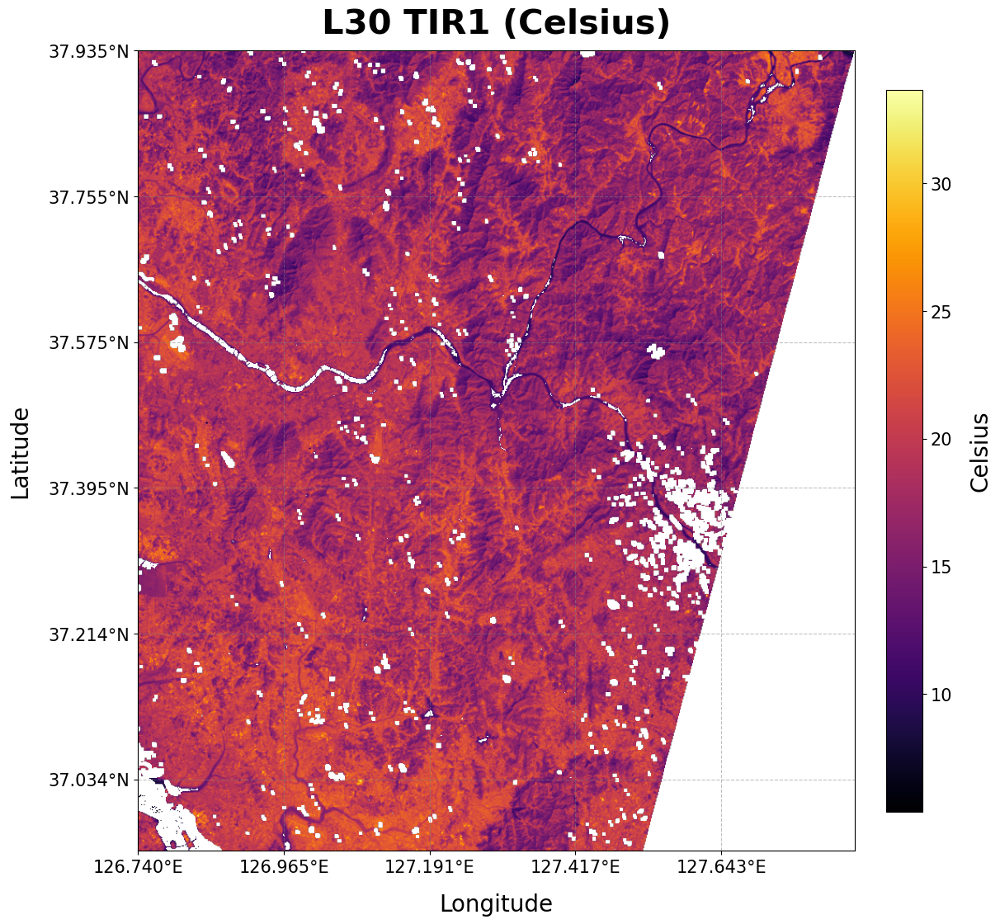

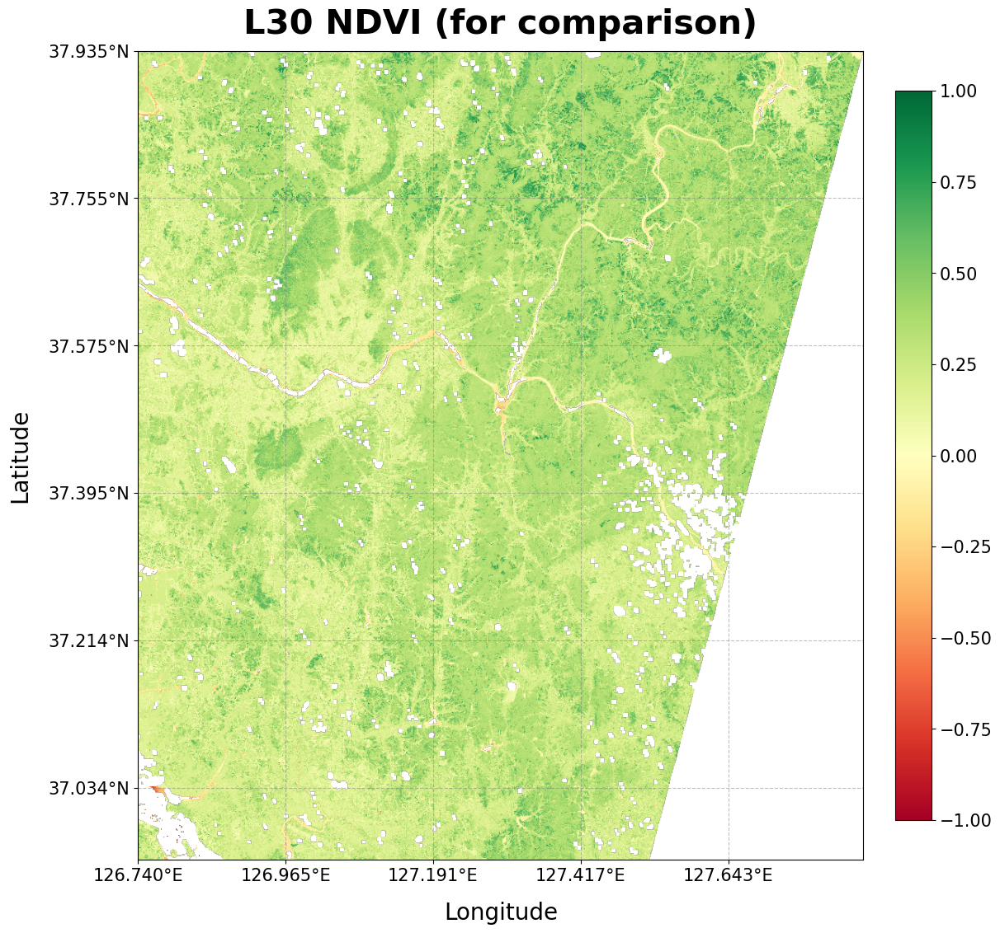

In [31]:
tir1 = np.where(roi_mask, crop(l30["tir1"][0]), np.nan)

print(f"L30 TIR1 ({l30['tir1'][3]}): mean={np.nanmean(tir1):.1f}, min={np.nanmin(tir1):.1f}, max={np.nanmax(tir1):.1f}")

show_image(decimate(tir1), f"L30 TIR1 ({l30['tir1'][3]})", cmap="inferno", colorbar_label=l30["tir1"][3])
show_image(decimate(ndvi_l30), "L30 NDVI (for comparison)", cmap="RdYlGn", vmin=-1, vmax=1)

### 6b. S30-only: red edge (NDRE)

Sentinel-2 MSI carries three red-edge bands that Landsat OLI does not have. NDRE (Normalized Difference Red Edge) substitutes red edge 1 (B05) for the red band in the NDVI formula:

`NDRE = (B08 - B05) / (B08 + B05)`

Red edge reflectance is more sensitive to canopy chlorophyll content/stress than the red band, so NDRE and NDVI are correlated but not identical. Comparing them shows where S30's extra spectral bands add information NDVI alone does not capture.

S30 NDRE: mean=0.203, std=0.110


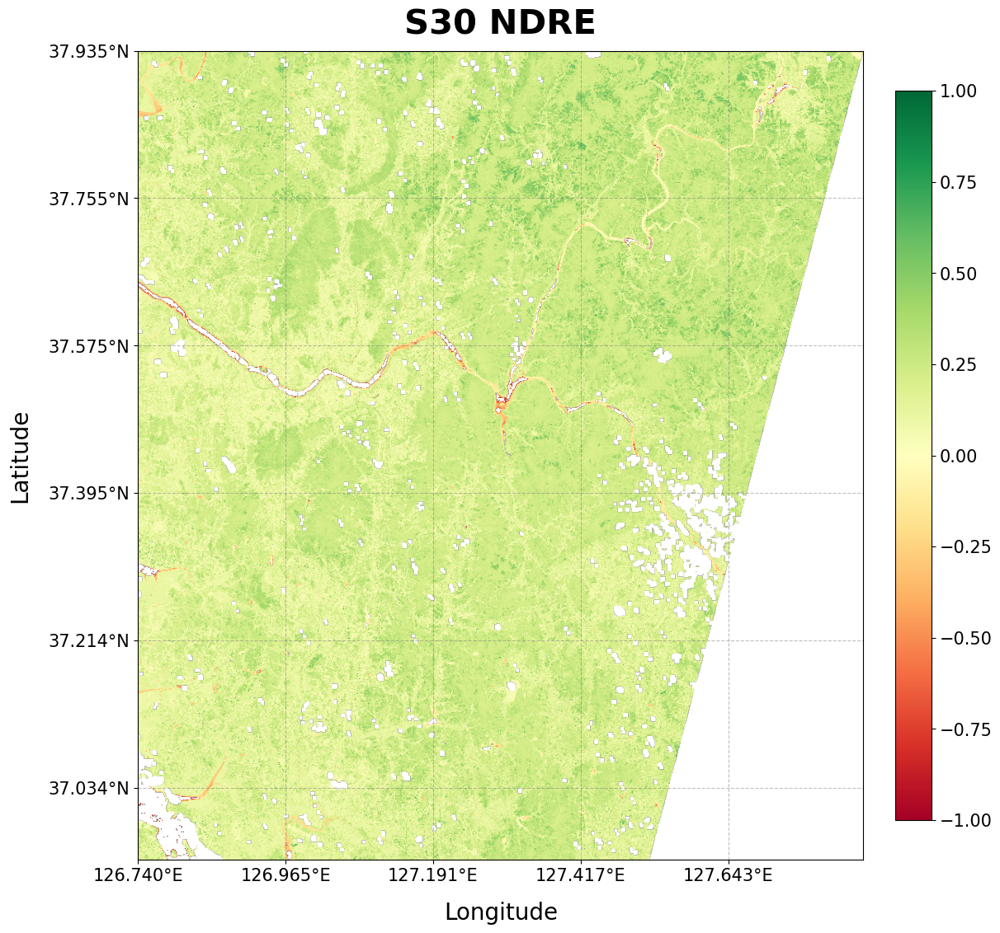

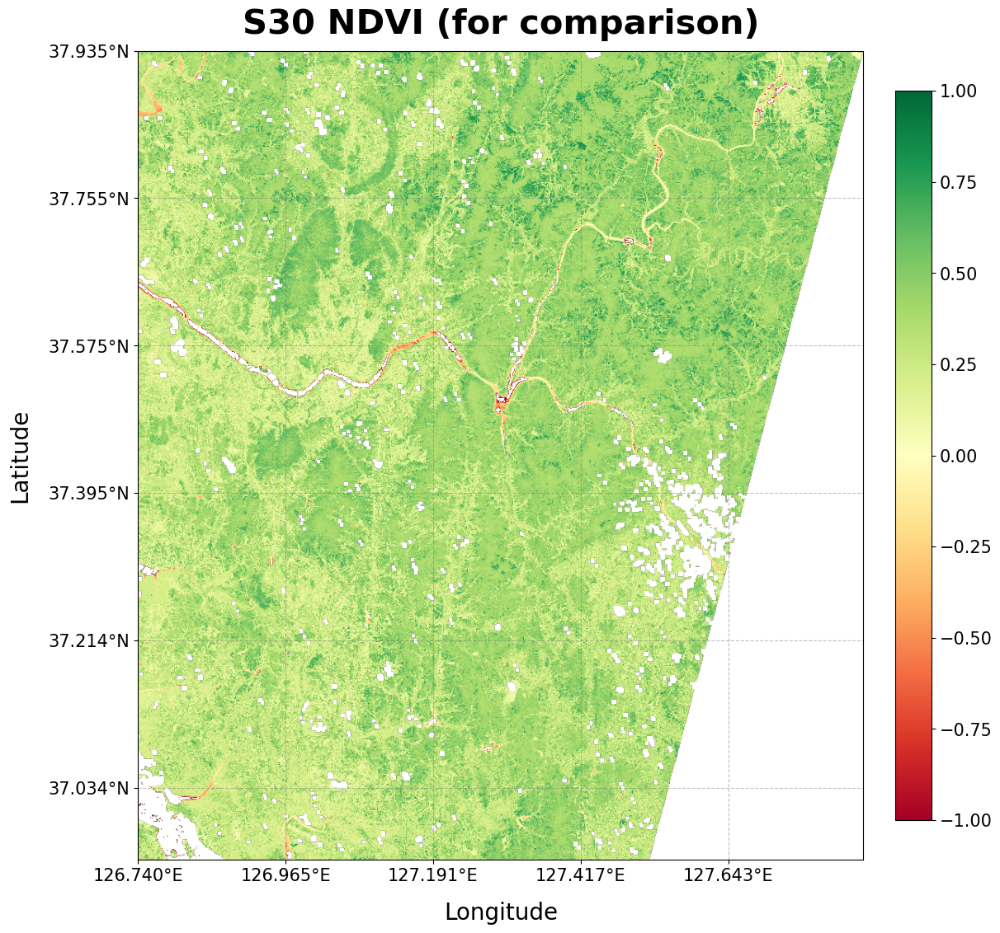

In [32]:
ndre_mask = (
    roi_mask
    & in_reflectance_range(crop(s30["nir_broad"][0])) & in_reflectance_range(crop(s30["red_edge1"][0]))
)
ndre = np.where(ndre_mask, normalized_difference(crop(s30["nir_broad"][0]), crop(s30["red_edge1"][0])), np.nan)

print(f"S30 NDRE: mean={np.nanmean(ndre):.3f}, std={np.nanstd(ndre):.3f}")

show_image(decimate(ndre), "S30 NDRE", cmap="RdYlGn", vmin=-1, vmax=1)
show_image(decimate(ndvi_s30), "S30 NDVI (for comparison)", cmap="RdYlGn", vmin=-1, vmax=1)

## Summary

- L30 and S30 share an identical UTM grid for a given tile, so the products are harmonized at the format and grid level.
- What still differs pair-to-pair is **coverage**: swath gaps and cloud/shadow fraction are independent per acquisition, so any pixel-level comparison needs an explicit valid-footprint intersection (Section 3), not just a grid check.
- The cross-sensor NDVI agreement (Section 5) is a useful harmonization check, but the residual difference reflects the 11-day gap and differing sun/view geometry as much as any sensor discrepancy. It should not be read as pure sensor bias.
- The two products are complementary, not redundant: L30's thermal bands and S30's red-edge bands each expose information the other sensor cannot provide.